In [8]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [28]:
FILE_PATH = '/content/drive/MyDrive/PERC_mendelly.csv'

In [10]:
# === IMPORTS ===
import pandas as pd
import numpy as np
import re
import os
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from scipy import sparse
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [13]:
# === IMPORTS ===
import pandas as pd
import numpy as np
import re
import os
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from scipy import sparse
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords

# === 1) Load dataset ===
if not os.path.exists(FILE_PATH):
    raise FileNotFoundError(f"CSV not found at {FILE_PATH}. Update FILE_PATH variable.")

try:
    df = pd.read_csv(FILE_PATH, encoding='utf-8')
except UnicodeDecodeError:
    try:
        df = pd.read_csv(FILE_PATH, encoding='latin-1')
    except Exception as e:
        raise SystemError(f"Could not read CSV with utf-8 or latin-1 encoding: {e}")


print("Columns in dataset:", df.columns.tolist())

# Use 'peom' as text column and 'Emotion' as label column.
# Add fallback: if 'peom' not present but 'poem' is, use that.
text_col = 'peom'
if text_col not in df.columns and 'poem' in df.columns:
    text_col = 'poem'
if text_col not in df.columns:
    raise ValueError(f"Neither 'peom' nor 'poem' column found. Found: {df.columns.tolist()}")

label_col = 'Emotion'
if label_col not in df.columns:
    raise ValueError(f"Label column '{label_col}' not found. Found: {df.columns.tolist()}")

# Drop rows with missing text or label
df = df[[text_col, label_col]].dropna().reset_index(drop=True)
df[text_col] = df[text_col].astype(str)
print(f"Loaded {len(df)} rows")

# === 2) Simple preprocessing function ===
stop_words = set(stopwords.words('english'))

def clean_text(s):
    s = s.lower()
    s = re.sub(r'\[.*?\]', '', s)                # remove content in brackets
    s = re.sub(r'http\S+|www.\S+', '', s)        # remove urls
    s = re.sub(r'[^a-z\s]', ' ', s)              # keep letters only
    tokens = s.split()
    tokens = [t for t in tokens if t not in stop_words and len(t) > 1]
    return ' '.join(tokens)

# Apply cleaning
df['clean_text'] = df[text_col].apply(clean_text)
print("Sample cleaned text:\n", df['clean_text'].head(3).tolist())

# === 3) Encode labels to integers ===
le = LabelEncoder()
df['label'] = le.fit_transform(df[label_col].astype(str))
label_mapping = dict(zip(le.classes_, le.transform(le.classes_)))
print("Label mapping (string -> int):", label_mapping)

X_text = df['clean_text'].values
y = df['label'].values

# === 4) Train/Val/Test split (70/15/15) with stratify ===
X_train_text, X_temp_text, y_train, y_temp = train_test_split(
    X_text, y, test_size=0.30, random_state=42, stratify=y
)
# split temp into val & test (50% of temp each -> 15% each)
X_val_text, X_test_text, y_val, y_test = train_test_split(
    X_temp_text, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

print("Sizes -> Train:", len(X_train_text), "Val:", len(X_val_text), "Test:", len(X_test_text))

# === 5) TF-IDF vectorization (fit on train only) ===
tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1,2))
X_train = tfidf.fit_transform(X_train_text)
X_val = tfidf.transform(X_val_text)
X_test = tfidf.transform(X_test_text)

print("TF-IDF shapes:", X_train.shape, X_val.shape, X_test.shape)

# === 6) Helper: evaluate & print metrics ===
label_names = [str(c) for c in le.classes_]  # class names for reports

def eval_and_print(name, model, X_tr, y_tr, X_v, y_v, X_t, y_t, do_cv=True, cv=5):
    print("\n" + "="*80)
    print("MODEL:", name)
    if do_cv:
        try:
            cv_scores = cross_val_score(model, X_tr, y_tr, cv=cv, n_jobs=-1)
            print(f"Cross-val ({cv} folds) mean acc: {cv_scores.mean():.4f} std: {cv_scores.std():.4f}")
        except Exception as e:
            print("CV failed:", e)

    # Fit full training set
    model.fit(X_tr, y_tr)

    # Training acc
    y_tr_pred = model.predict(X_tr)
    print("Train Acc:", accuracy_score(y_tr, y_tr_pred))

    # Validation evaluation
    y_val_pred = model.predict(X_v)
    print("Val Acc:", accuracy_score(y_v, y_val_pred))
    print("Val Classification Report:")
    print(classification_report(y_v, y_val_pred, target_names=label_names, zero_division=0))
    print("Val Confusion Matrix:\n", confusion_matrix(y_v, y_val_pred))

    # Test evaluation
    y_test_pred = model.predict(X_t)
    print("Test Acc:", accuracy_score(y_t, y_test_pred))
    print("Test Classification Report:")
    print(classification_report(y_t, y_test_pred, target_names=label_names, zero_division=0))
    print("Test Confusion Matrix:\n", confusion_matrix(y_t, y_test_pred))
    return model, y_val_pred, y_test_pred

# === 7) Define models ===
models = {
    "SVM_linear": SVC(kernel='linear', C=1.0, random_state=42),
    "LogisticRegression": LogisticRegression(max_iter=2000, multi_class='multinomial', solver='saga', C=1.0, random_state=42),
    "RandomForest": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    "MultinomialNB": MultinomialNB(alpha=1.0),
    "KNN": KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
}

# === 8) Train & evaluate each model ===
from sklearn.exceptions import NotFittedError
results = {}

# For KNN: convert to dense but reduce dimension via TruncatedSVD to avoid memory issues
is_sparse = sparse.issparse(X_train)
svd_for_knn = None
if is_sparse:
    # choose a reasonable SVD components number (e.g., 200)
    svd_n = 200
    print(f"Data is sparse. Will use TruncatedSVD(n_components={svd_n}) for KNN.")
    svd_for_knn = TruncatedSVD(n_components=svd_n, random_state=42)
    X_train_knn = svd_for_knn.fit_transform(X_train)
    X_val_knn = svd_for_knn.transform(X_val)
    X_test_knn = svd_for_knn.transform(X_test)
else:
    X_train_knn = X_train
    X_val_knn = X_val
    X_test_knn = X_test

for name, model in models.items():
    print("\n" + "#"*60)
    if name == "KNN":
        m, vy, ty = eval_and_print(name, model, X_train_knn, y_train, X_val_knn, y_val, X_test_knn, y_test, do_cv=True)
    else:
        m, vy, ty = eval_and_print(name, model, X_train, y_train, X_val, y_val, X_test, y_test, do_cv=True)
    results[name] = {
        "model": m,
        "y_val_pred": vy,
        "y_test_pred": ty
    }

# === 9) Save label encoder mapping and TF-IDF vectorizer for later use (optional) ===
import joblib
joblib.dump(tfidf, '/content/drive/MyDrive/poem_tfidf_vectorizer.joblib')
joblib.dump(le, '/content/drive/MyDrive/poem_label_encoder.joblib')
# Save one of the trained models (e.g., RandomForest)
joblib.dump(results['RandomForest']['model'], '/content/drive/MyDrive/poem_rf_model.joblib')

print("\nFinished training & evaluation. Vectorizer, label-encoder, and RF model saved to Drive.")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Columns in dataset: ['Poem', 'Emotion']
Loaded 716 rows
Sample cleaned text:
 ['tree tree beside sandy river beach holds topmost boughs like fingers towards skies cannot reach earth bound heaven amorous soul man body brain hungry earth heavenly flight detain', 'sri krishna immense light thou spirit wide boundless space clasped hid deathless limbs gloried face vainly lie space time void none vainly strive self world crying alone one self self soul space fount time heart hearts mind minds alone sits sublime oh void absolute self absorbed splendid mute hands clasp hold red lips kiss blow flute loves moves many limbs sate whims hear sweet ecstasy two one two know difference rich sense two clasp one strange mystery', 'blue sky green forest whose hand painted glow winds asleep womb ether roused bade blow lost heart cavern nature found brain builds thought pattern bloom flowers woven luminous net stars caught strength man beauty woman laugh boy blush girl hand sent jupiter spinning heaven spe

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Train Acc: 0.8602794411177644
Val Acc: 0.37383177570093457
Val Classification Report:
              precision    recall  f1-score   support

       anger       1.00      0.14      0.25         7
     courage       0.50      0.09      0.15        11
        fear       0.00      0.00      0.00         4
        hate       0.00      0.00      0.00         4
         joy       0.58      0.37      0.45        19
        love       0.39      0.67      0.49        24
       peace       0.75      0.25      0.38        12
         sad       0.26      0.52      0.34        23
    surprise       0.00      0.00      0.00         3

    accuracy                           0.37       107
   macro avg       0.39      0.23      0.23       107
weighted avg       0.45      0.37      0.34       107

Val Confusion Matrix:
 [[ 1  1  0  0  0  0  0  5  0]
 [ 0  1  0  0  1  4  0  5  0]
 [ 0  0  0  0  0  0  0  4  0]
 [ 0  0  0  0  0  2  0  2  0]
 [ 0  0  0  0  7  5  0  7  0]
 [ 0  0  0  0  0 16  1  7  0]
 [ 0  

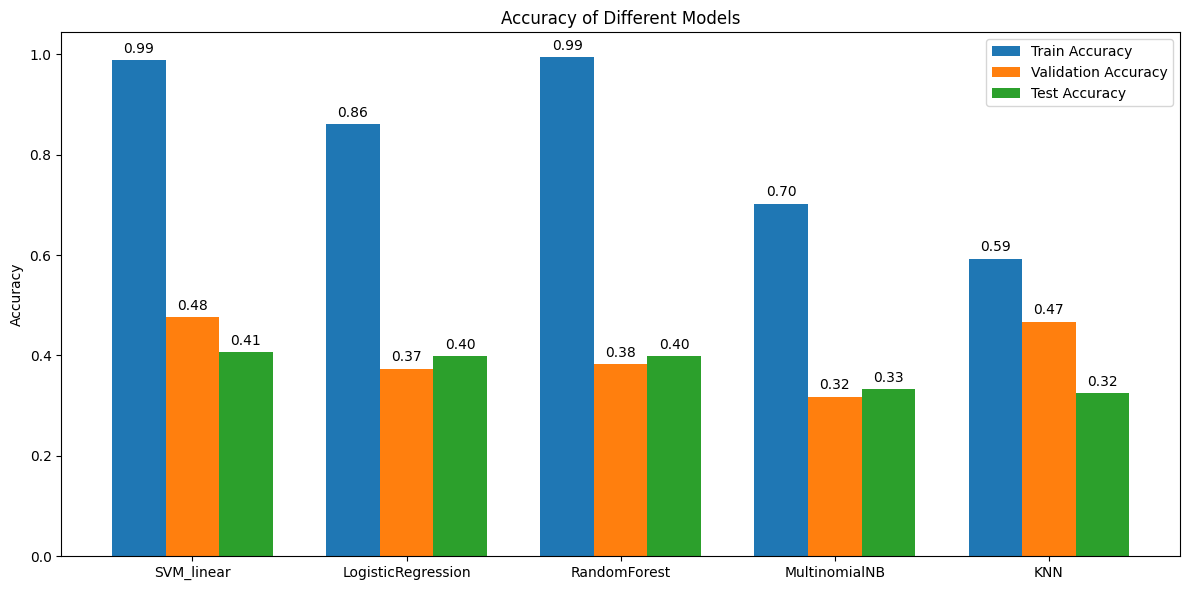

In [15]:
import matplotlib.pyplot as plt

# Extract accuracy and validation accuracy from results
model_names = list(results.keys())
train_accuracies = []
val_accuracies = []
test_accuracies = []

for name in model_names:
    model = results[name]['model']
    y_val_pred = results[name]['y_val_pred']
    y_test_pred = results[name]['y_test_pred']

    if name == 'KNN':
        # Use SVD-transformed data for KNN evaluation
        train_acc = model.score(X_train_knn, y_train)
        val_acc = accuracy_score(y_val, y_val_pred)
        test_acc = accuracy_score(y_test, y_test_pred)
    else:
        # Use original TF-IDF data for other models
        train_acc = model.score(X_train, y_train)
        val_acc = accuracy_score(y_val, y_val_pred)
        test_acc = accuracy_score(y_test, y_test_pred)


    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)
    test_accuracies.append(test_acc)


# Plotting
x = np.arange(len(model_names))  # the label locations
width = 0.25  # the width of the bars

fig, ax = plt.subplots(figsize=(12, 6))
rects1 = ax.bar(x - width, train_accuracies, width, label='Train Accuracy')
rects2 = ax.bar(x, val_accuracies, width, label='Validation Accuracy')
rects3 = ax.bar(x + width, test_accuracies, width, label='Test Accuracy')

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_ylabel('Accuracy')
ax.set_title('Accuracy of Different Models')
ax.set_xticks(x)
ax.set_xticklabels(model_names)
ax.legend()

ax.bar_label(rects1, padding=3, fmt='%.2f')
ax.bar_label(rects2, padding=3, fmt='%.2f')
ax.bar_label(rects3, padding=3, fmt='%.2f')

fig.tight_layout()
plt.show()

In [22]:
# === 10) Predict emotion for new input ===

def predict_emotion(poem_text, models, tfidf_vectorizer, label_encoder, svd_transformer=None):
    """Predicts the emotion of a given poem text using trained models.

    Args:
        poem_text (str): The input poem text.
        models (dict): A dictionary of trained models.
        tfidf_vectorizer: The fitted TF-IDF vectorizer.
        label_encoder: The fitted label encoder.
        svd_transformer: The fitted TruncatedSVD transformer (for KNN).

    Returns:
        dict: A dictionary containing predictions from each model.
    """
    # Preprocess the input text
    cleaned_poem = clean_text(poem_text)

    # Transform the cleaned text using TF-IDF
    X_new = tfidf_vectorizer.transform([cleaned_poem])

    predictions = {}
    for name, model in models.items():
        if name == "KNN" and svd_transformer:
            # Transform with SVD for KNN
            X_new_knn = svd_transformer.transform(X_new)
            predicted_label_int = model.predict(X_new_knn)[0]
        else:
            predicted_label_int = model.predict(X_new)[0]

        # Convert predicted label back to original string emotion
        predicted_emotion = label_encoder.inverse_transform([predicted_label_int])[0]
        predictions[name] = predicted_emotion

    return predictions

# Example Usage:
# input_poem = "In our own tracks of ambition We will reach the destination Let not distance lead to deterioration So make our pain a celebration In the way, if we face confrontation Will not indulge in accusation We'll laugh away the humiliation Just without any hesitation Life is all about imagination Would we ruin by frustration? And go back to nullification! No, we'll get positivity from provocation Thus keep on doing experimentation Until we find a solution Success and failure are in close juxtaposition Our goal is our selection Never will we lower expectation My dear, we will not be overwhelmed by mortification Each era has its cessation Returing life to its jollification And when the voluminous but dusty recollection Will erect around us, an iron fortification Causing nostalgic suffocation We to avoid asphyxiation Will put up ventilation Then through the ventilation Will carry out inspection And solve by retrospection The yester reservation To ourself, will submit confession Of our desperation Then from the deprivation We'll make new resolution Under the shade of determination And utter the words of conviction With sincere and devout dedication Thus smile with relaxation My dear, we will not be overwhelmed by mortification Each era has its cessation Returning life to jollification"
# input_poem = "I am feeling very sad and lonely today."
input_poem = "The world is a dangerous place, full of fear."


# Make predictions using all models
# Note: For KNN, we need to pass the svd_for_knn transformer
model_predictions = predict_emotion(input_poem, models, tfidf, le, svd_for_knn if 'KNN' in models else None)

print(f"Input Poem: '{input_poem}'")
print("\nEmotion Predictions:")
for model_name, emotion in model_predictions.items():
    print(f"- {model_name}: {emotion}")

Input Poem: 'The world is a dangerous place, full of fear.'

Emotion Predictions:
- SVM_linear: joy
- LogisticRegression: sad
- RandomForest: joy
- MultinomialNB: love
- KNN: fear


In [24]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    sublinear_tf=True,
    min_df=2,
    max_df=0.8,
    ngram_range=(1, 3),  # include unigrams, bigrams, trigrams
    analyzer='word',
    stop_words='english'
)


In [25]:
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

svm_pipeline = Pipeline([
    ('svd', TruncatedSVD(n_components=300, random_state=42)),
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=8, gamma='scale', class_weight='balanced'))
])


In [26]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(svm_pipeline, X_train, y_train, cv=cv, scoring='accuracy')
print("CV Accuracy: ", cv_scores.mean())


CV Accuracy:  0.2475049504950495


In [27]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'svd__n_components': [200, 300, 400],
    'svm__C': [2, 4, 8, 16],
    'svm__gamma': ['scale', 0.01, 0.001],
    'svm__kernel': ['rbf', 'linear']
}

grid = GridSearchCV(svm_pipeline, param_grid, cv=cv, n_jobs=-1, scoring='accuracy')
grid.fit(X_train, y_train)

print("Best CV Accuracy:", grid.best_score_)
print("Best Params:", grid.best_params_)


Best CV Accuracy: 0.4451485148514852
Best Params: {'svd__n_components': 200, 'svm__C': 16, 'svm__gamma': 0.001, 'svm__kernel': 'rbf'}


In [29]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=50,
    min_samples_split=2,
    min_samples_leaf=1,
    class_weight='balanced_subsample',
    random_state=42
)


##Second


In [ ]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import TruncatedSVD
from sklearn.base import TransformerMixin

# === 5) Combine word-level and character-level TF-IDF ===
word_tfidf = TfidfVectorizer(
    sublinear_tf=True,
    strip_accents='unicode',
    analyzer='word',
    token_pattern=r'\w{1,}',
    stop_words='english',
    ngram_range=(1, 2),
    max_features=20000
)

char_tfidf = TfidfVectorizer(
    sublinear_tf=True,
    strip_accents='unicode',
    analyzer='char_wb',
    ngram_range=(3, 5),
    max_features=10000
)

combined_features = FeatureUnion([
    ("word_tfidf", word_tfidf),
    ("char_tfidf", char_tfidf)
])

X_train = combined_features.fit_transform(X_train_text)
X_val = combined_features.transform(X_val_text)
X_test = combined_features.transform(X_test_text)

print("Combined TF-IDF shape:", X_train.shape)

# === 6) Dimensionality reduction for better generalization ===
svd = TruncatedSVD(n_components=300, random_state=42)
X_train_svd = svd.fit_transform(X_train)
X_val_svd = svd.transform(X_val)
X_test_svd = svd.transform(X_test)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_svd)
X_val_scaled = scaler.transform(X_val_svd)
X_test_scaled = scaler.transform(X_test_svd)

# === 7) Stronger tuned models ===
param_grids = {
    "SVM": {
        "model": SVC(class_weight='balanced', probability=True, random_state=42),
        "params": {
            "kernel": ["rbf", "linear"],
            "C": [0.5, 1, 2, 4, 6, 8],
            "gamma": ["scale", 0.01, 0.001]
        }
    },
    "RandomForest": {
        "model": RandomForestClassifier(random_state=42, n_jobs=-1),
        "params": {
            "n_estimators": [300, 500, 700],
            "max_depth": [30, 50, None],
            "min_samples_split": [2, 4],
            "min_samples_leaf": [1, 2],
            "bootstrap": [True, False]
        }
    }
}

# === 8) Cross-validation setup ===
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

best_models = {}

for name, cfg in param_grids.items():
    print("\n" + "="*80)
    print(f"🔍 Tuning {name} ...")
    X_used = X_train_scaled if name == "SVM" else X_train_svd
    grid = GridSearchCV(
        cfg["model"],
        cfg["params"],
        scoring="accuracy",
        cv=cv,
        n_jobs=-1,
        verbose=2
    )
    grid.fit(X_used, y_train)
    print(f"✅ Best {name} params:", grid.best_params_)
    print(f"✅ Best CV accuracy: {grid.best_score_:.4f}")
    best_models[name] = grid.best_estimator_

# === 9) Evaluate tuned models ===
results = {}
for name, model in best_models.items():
    print("\n" + "#"*70)
    print(f"Evaluating tuned {name} model...")
    X_v = X_val_scaled if name == "SVM" else X_val_svd
    X_t = X_test_scaled if name == "SVM" else X_test_svd
    m, vy, ty = eval_and_print(name, model, X_train_scaled if name=="SVM" else X_train_svd,
                               y_train, X_v, y_val, X_t, y_test, do_cv=False)
    results[name] = {"model": m, "y_val_pred": vy, "y_test_pred": ty}

# === 10) Save the best-performing model ===
best_name = max(results, key=lambda k: accuracy_score(y_val, results[k]['y_val_pred']))
joblib.dump(results[best_name]['model'], f'/content/drive/MyDrive/poem_best_{best_name}.joblib')
print(f"\n✅ Saved best model: {best_name}")


Combined TF-IDF shape: (501, 30000)

🔍 Tuning SVM ...
Fitting 5 folds for each of 36 candidates, totalling 180 fits
✅ Best SVM params: {'C': 2, 'gamma': 0.001, 'kernel': 'rbf'}
✅ Best CV accuracy: 0.3554

🔍 Tuning RandomForest ...
Fitting 5 folds for each of 72 candidates, totalling 360 fits


In [ ]:
import matplotlib.pyplot as plt

# Extract accuracy and validation accuracy from results
model_names = list(results.keys())
train_accuracies = []
val_accuracies = []
test_accuracies = []

for name in model_names:
    model = results[name]['model']
    y_val_pred = results[name]['y_val_pred']
    y_test_pred = results[name]['y_test_pred']

    if name == 'KNN':
        # Use SVD-transformed data for KNN evaluation
        train_acc = model.score(X_train_knn, y_train)
        val_acc = accuracy_score(y_val, y_val_pred)
        test_acc = accuracy_score(y_test, y_test_pred)
    else:
        # Use original TF-IDF data for other models
        train_acc = model.score(X_train, y_train)
        val_acc = accuracy_score(y_val, y_val_pred)
        test_acc = accuracy_score(y_test, y_test_pred)


    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)
    test_accuracies.append(test_acc)


# Plotting
x = np.arange(len(model_names))  # the label locations
width = 0.25  # the width of the bars

fig, ax = plt.subplots(figsize=(12, 6))
rects1 = ax.bar(x - width, train_accuracies, width, label='Train Accuracy')
rects2 = ax.bar(x, val_accuracies, width, label='Validation Accuracy')
rects3 = ax.bar(x + width, test_accuracies, width, label='Test Accuracy')

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_ylabel('Accuracy')
ax.set_title('Accuracy of Different Models')
ax.set_xticks(x)
ax.set_xticklabels(model_names)
ax.legend()

ax.bar_label(rects1, padding=3, fmt='%.2f')
ax.bar_label(rects2, padding=3, fmt='%.2f')
ax.bar_label(rects3, padding=3, fmt='%.2f')

fig.tight_layout()
plt.show()

In [ ]:
# === 10) Predict emotion for new input ===

def predict_emotion(poem_text, models, tfidf_vectorizer, label_encoder, svd_transformer=None):
    """Predicts the emotion of a given poem text using trained models.

    Args:
        poem_text (str): The input poem text.
        models (dict): A dictionary of trained models.
        tfidf_vectorizer: The fitted TF-IDF vectorizer.
        label_encoder: The fitted label encoder.
        svd_transformer: The fitted TruncatedSVD transformer (for KNN).

    Returns:
        dict: A dictionary containing predictions from each model.
    """
    # Preprocess the input text
    cleaned_poem = clean_text(poem_text)

    # Transform the cleaned text using TF-IDF
    X_new = tfidf_vectorizer.transform([cleaned_poem])

    predictions = {}
    for name, model in models.items():
        if name == "KNN" and svd_transformer:
            # Transform with SVD for KNN
            X_new_knn = svd_transformer.transform(X_new)
            predicted_label_int = model.predict(X_new_knn)[0]
        else:
            predicted_label_int = model.predict(X_new)[0]

        # Convert predicted label back to original string emotion
        predicted_emotion = label_encoder.inverse_transform([predicted_label_int])[0]
        predictions[name] = predicted_emotion

    return predictions

# Example Usage:
# input_poem = "In our own tracks of ambition We will reach the destination Let not distance lead to deterioration So make our pain a celebration In the way, if we face confrontation Will not indulge in accusation We'll laugh away the humiliation Just without any hesitation Life is all about imagination Would we ruin by frustration? And go back to nullification! No, we'll get positivity from provocation Thus keep on doing experimentation Until we find a solution Success and failure are in close juxtaposition Our goal is our selection Never will we lower expectation My dear, we will not be overwhelmed by mortification Each era has its cessation Returing life to its jollification And when the voluminous but dusty recollection Will erect around us, an iron fortification Causing nostalgic suffocation We to avoid asphyxiation Will put up ventilation Then through the ventilation Will carry out inspection And solve by retrospection The yester reservation To ourself, will submit confession Of our desperation Then from the deprivation We'll make new resolution Under the shade of determination And utter the words of conviction With sincere and devout dedication Thus smile with relaxation My dear, we will not be overwhelmed by mortification Each era has its cessation Returning life to jollification"
# input_poem = "I am feeling very sad and lonely today."
input_poem = "The world is a dangerous place, full of fear."


# Make predictions using all models
# Note: For KNN, we need to pass the svd_for_knn transformer
model_predictions = predict_emotion(input_poem, models, tfidf, le, svd_for_knn if 'KNN' in models else None)

print(f"Input Poem: '{input_poem}'")
print("\nEmotion Predictions:")
for model_name, emotion in model_predictions.items():
    print(f"- {model_name}: {emotion}")